# Livrable 3, partie 2 : BLIP, le modèle retenu

Groupe :
* Isrâ BOUDEMAGH
* Théophile NOEL
* Bruno RIECKENBERG
* Corentin ROMANO

## Objectif

La partie 1 (`L3_1_modele_workshops.ipynb`) a reconstruit le modèle des workshops (CNN pré-entraîné + attention +
décodeur GRU entraîné sur MS COCO) et montré qu'**il ne fonctionne pas correctement** : légendes génériques ou fausses,
sur-apprentissage, échec complet sur les images du projet. La cause est la méthode elle-même : le transfer learning ne
porte que sur la vision, la langue est apprise de zéro sur quelques milliers de phrases.

Ce notebook va au bout du transfer learning : il utilise **BLIP**, un modèle **déjà entraîné pour la vision ET pour la
langue** sur des millions d'images légendées, le compare au modèle 1 **sur les mêmes images**, puis l'**enregistre dans
`models/`** : c'est lui qu'utilisent l'onglet L3 du site de test et l'étape 3 de la pipeline.

| Partie | Contenu |
|---|---|
| 8 | **Modèle 2 : BLIP** (fonctionnement détaillé), chargement, génération des légendes |
| 9 | **Comparaison des deux modèles** sur les mêmes images de test COCO et sur les images du projet |
| 10 | **Conclusion** et **enregistrement de BLIP** dans `models/` |

Ce notebook n'utilise que **PyTorch** et **Transformers** (pas TensorFlow) : lancer d'abord la partie 1, qui enregistre
dans `models/l3_attention_resultats.json` les légendes et les scores du modèle 1. Sans ce fichier, BLIP est évalué seul.

In [1]:
# Bibliothèques : PyTorch + Transformers (Hugging Face) pour BLIP, NumPy / Pandas pour les calculs et tableaux,
# Matplotlib pour les figures. Pas de TensorFlow ici : le modèle 1 est dans L3_1_modele_workshops.ipynb.
import collections
import faulthandler
import gc
import json
import math
import os
import pathlib
import random
import shutil
import sys
import time

# Si le noyau s'arrête net (erreur de mémoire du code C, bibliothèque CUDA...), Python écrit au moins la ligne en cause
# dans le journal du noyau (VS Code : panneau Sortie > Jupyter) au lieu d'un simple « Kernel crashed ».
faulthandler.enable(file=sys.__stderr__)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image
from transformers import BlipForConditionalGeneration, BlipProcessor

# Utiliser la carte graphique lorsqu'elle est disponible ; définir L3_USE_GPU=0 pour forcer le processeur.
UTILISER_GPU = os.environ.get("L3_USE_GPU", "1") == "1"
blip_device = torch.device("cuda" if UTILISER_GPU and torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, Transformers {transformers.__version__}")
print("Calcul sur :", f"carte graphique ({torch.cuda.get_device_name(0)})" if blip_device.type == "cuda" else "processeur")


def memoire_utilisee():
    "Mémoire vive occupée par ce noyau, en Go (None si on ne sait pas la lire)."
    try:
        with open("/proc/self/status") as f:
            return next(int(l.split()[1]) / 2**20 for l in f if l.startswith("VmRSS"))
    except (OSError, StopIteration):
        return None

PyTorch 2.13.0+cu129, Transformers 5.20.1
Calcul sur : carte graphique (NVIDIA GeForce RTX 5070 Laptop GPU)


In [2]:
# ----- Paramètres, les mêmes que dans la partie 1 (même graine, même sous-ensemble d'images, même découpage) -----
SEED = 42
MAX_IMAGES = int(os.environ.get("L3_MAX_IMAGES", 5000))    # images COCO utilisées au plus (comme le workshop)
N_EVAL = int(os.environ.get("L3_N_EVAL", 0))               # images de test évaluées (0 = tout le jeu de test)

COCO_CANDIDATS = [os.environ.get("L3_COCO", ""), ".", "./dataset", "../../workshop"]
MODELS_DIR = pathlib.Path("../models")                     # TOUS les modèles du projet
TEST_PHOTOS = pathlib.Path("../Test_photos")               # 12 images du projet, jamais vues par aucun des modèles
BLIP_DIR = MODELS_DIR / "blip-captioning-base"             # BLIP enregistré (version utilisée par le site et la pipeline)
BLIP_HUB = "Salesforce/blip-image-captioning-base"         # le même modèle sur le hub Hugging Face
RESULTATS_MODELE_1 = MODELS_DIR / "l3_attention_resultats.json"   # écrit par L3_1_modele_workshops.ipynb

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Rappel : les données et la mesure de la partie 1

Pour comparer les deux modèles sur **les mêmes images avec la même mesure**, on reprend ici, à l'identique, trois
morceaux de la partie 1 : la lecture de MS COCO 2014 (5 légendes par image), le découpage reproductible par image
(80 % entraînement, 10 % validation, 10 % test, même graine) et le calcul du **BLEU** et de la **diversité** des légendes.
Leur explication détaillée est dans la partie 1 (sections 1, 3 et 6).

In [3]:
# Dossier COCO : le premier candidat qui contient annotations/captions_train2014.json et train2014/
def trouver_coco():
    for c in COCO_CANDIDATS:
        if c and (pathlib.Path(c) / "annotations" / "captions_train2014.json").is_file() and (pathlib.Path(c) / "train2014").is_dir():
            return pathlib.Path(c)
    raise FileNotFoundError(f"Données COCO introuvables. Emplacements testés : {[c for c in COCO_CANDIDATS if c]}")

COCO_DIR = trouver_coco()
with open(COCO_DIR / "annotations" / "captions_train2014.json", encoding="utf-8") as f:
    annotations = json.load(f)

# Regrouper les légendes par image (5 par image en général)
legendes_par_image = collections.defaultdict(list)
for a in annotations["annotations"]:
    nom = f"COCO_train2014_{a['image_id']:012d}.jpg"
    legendes_par_image[nom].append(a["caption"].strip())

# Images présentes sur le disque, triées (ordre reproductible), puis sous-ensemble de MAX_IMAGES images
presentes = {e.name for e in os.scandir(COCO_DIR / "train2014") if e.name.lower().endswith(".jpg")}
noms_images = sorted(n for n in legendes_par_image if n in presentes)[:MAX_IMAGES]
chemins_images = {n: str(COCO_DIR / "train2014" / n) for n in noms_images}
n_legendes = sum(len(legendes_par_image[n]) for n in noms_images)
print(f"Données : {COCO_DIR.resolve()}")
print(f"{len(annotations['images'])} images annotées dans le fichier, {len(presentes)} présentes sur le disque")
del annotations   # le fichier complet (414 000 légendes) n'est plus utile : on libère la mémoire
print(f"Sous-ensemble utilisé : {len(noms_images)} images, {n_legendes} légendes")

FILTRES = '!"#$%&()*+.,-/:;=?@[\\]^_`{|}~'   # ponctuation retirée, comme le Tokenizer du workshop
TABLE_FILTRES = str.maketrans({c: " " for c in FILTRES})

def mots(texte):
    "Découpe une phrase en mots : minuscules, ponctuation retirée (même règle que le Tokenizer Keras du workshop)."
    return texte.lower().translate(TABLE_FILTRES).split()


# Découpage par image, reproductible (même code que la partie 1)
ordre = noms_images[:]
random.Random(SEED).shuffle(ordre)
n_train, n_val = int(0.8 * len(ordre)), int(0.1 * len(ordre))
images_train, images_val, images_test = ordre[:n_train], ordre[n_train:n_train + n_val], ordre[n_train + n_val:]
if N_EVAL:
    images_test = images_test[:N_EVAL]
exemples = images_test[:8]
print(f"Images : {len(images_train)} entraînement, {len(images_val)} validation, {len(images_test)} test")

Données : /mnt/d/A5/projet/Livrable3
82783 images annotées dans le fichier, 3611 présentes sur le disque
Sous-ensemble utilisé : 3611 images, 18065 légendes
Images : 2888 entraînement, 361 validation, 362 test


In [4]:
def ngrammes(m, n):
    return collections.Counter(tuple(m[i:i + n]) for i in range(len(m) - n + 1))


def bleu(candidats, references, n_max=4):
    "BLEU de corpus (Papineni et al., 2002) : précisions n-grammes écrêtées, moyenne géométrique, pénalité de brièveté."
    num, den, c, r = [0] * n_max, [0] * n_max, 0, 0
    for h, refs in zip(candidats, references):
        c += len(h)
        r += min((abs(len(x) - len(h)), len(x)) for x in refs)[1]       # longueur de la référence la plus proche
        for n in range(1, n_max + 1):
            compte, maxi = ngrammes(h, n), collections.Counter()
            for x in refs:
                maxi |= ngrammes(x, n)
            num[n - 1] += sum(min(k, maxi[g]) for g, k in compte.items())
            den[n - 1] += max(len(h) - n + 1, 0)
    if c == 0: 
        return {f"BLEU-{n}": 0.0 for n in range(1, n_max + 1)}
    bp = 1.0 if c > r else math.exp(1 - r / c)
    precisions = [num[k] / den[k] if den[k] and num[k] else 1e-9 for k in range(n_max)]
    return {f"BLEU-{n}": bp * math.exp(sum(math.log(p) for p in precisions[:n]) / n) for n in range(1, n_max + 1)}


phrases_train = {tuple(mots(l)) for n in images_train for l in legendes_par_image[n]}

def evaluer(nom, candidats, images, ms=None):
    refs = [[mots(l) for l in legendes_par_image[n]] for n in images]
    ligne = {"modèle": nom, **bleu(candidats, refs)}
    ligne["légendes distinctes"] = len({tuple(c) for c in candidats}) / len(candidats)
    ligne["mots utilisés"] = len({m for c in candidats for m in c})
    ligne["phrases recopiées de l'entraînement"] = np.mean([tuple(c) in phrases_train for c in candidats])
    ligne["mots par légende"] = np.mean([len(c) for c in candidats])
    if ms is not None:
        ligne["ms par image"] = ms
    return ligne


# Référence humaine : une des 5 légendes comparée aux 4 autres (le score qu'obtiendrait une personne)
humain = evaluer("légende humaine (1 contre 4)", [mots(legendes_par_image[n][0]) for n in images_test], images_test)
humain.update(bleu([mots(legendes_par_image[n][0]) for n in images_test],
                   [[mots(l) for l in legendes_par_image[n][1:]] for n in images_test]))


# Résultats du modèle 1, enregistrés par la partie 1 sur les mêmes images de test
modele_1 = None
if RESULTATS_MODELE_1.is_file():
    modele_1 = json.loads(RESULTATS_MODELE_1.read_text(encoding="utf-8"))
    if modele_1["images_test"] != images_test:
        print(f"ATTENTION : {RESULTATS_MODELE_1} a été calculé sur d'autres images de test "
              f"(paramètres de la partie 1 : {modele_1['parametres']}) ; comparaison avec le modèle 1 ignorée.")
        modele_1 = None
else:
    print(f"{RESULTATS_MODELE_1} absent : lancer d'abord L3_1_modele_workshops.ipynb pour comparer BLIP au modèle 1.")

lignes = [humain]
if modele_1:
    lignes += [r for r in modele_1["resultats"] if r["modèle"].startswith("modèle 1")]
    m1_faisceau = modele_1["faisceau_test"]
    print(f"Modèle 1 : {modele_1['epoques']} époques d'entraînement ({modele_1['entrainement_min']:.0f} min), "
          f"{modele_1['parametres_entraines']:,} paramètres entraînés ; résultats relus pour {len(images_test)} images de test")
resultats = pd.DataFrame(lignes).set_index("modèle")
resultats.round(3)

Modèle 1 : 8 époques d'entraînement (3 min), 6,406,281 paramètres entraînés ; résultats relus pour 362 images de test


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,légendes distinctes,mots utilisés,phrases recopiées de l'entraînement,mots par légende,ms par image
modèle,,,,,,,,,
légende humaine (1 contre 4),0.632,0.438,0.298,0.202,0.994,873,0.014,10.768,NaN
"modèle 1, glouton, images d'entraînement",0.712,0.552,0.408,0.292,0.928,278,0.019,9.083,NaN
"modèle 1, glouton, test",0.591,0.413,0.281,0.191,0.906,224,0.008,9.075,1.740
"modèle 1, faisceau, test",0.622,0.441,0.305,0.211,0.892,250,0.033,8.743,257.045


## 8. Modèle 2 : BLIP

**BLIP** (*Bootstrapping Language-Image Pre-training*, Li et al., Salesforce, 2022,
[arXiv:2201.12086](https://arxiv.org/abs/2201.12086)) est un modèle **vision-langage pré-entraîné** : au lieu
d'apprendre à voir et à écrire à partir de nos 2 900 images, il a appris sur des **millions de couples image-texte**
(14 millions dans la version de base de l'article, jusqu'à 129 millions avec les images du web LAION), puis a été affiné
sur COCO pour écrire des légendes. On utilise la version publiée par Salesforce sur Hugging Face,
`Salesforce/blip-image-captioning-base` (architecture de base, encodeur d'image ViT-B/16), déjà enregistrée dans
`models/blip-captioning-base`.

Le principe reste celui du modèle 1 (un encodeur d'image, un décodeur qui écrit mot par mot en regardant l'image), mais
**chaque brique est remplacée par un Transformer pré-entraîné**.

```
 image 384×384 ──► ViT-B/16 : 576 morceaux 16×16 + [CLS] ──► 12 couches d'auto-attention ──► 577 vecteurs de 768
                                                                                                 │ (clés, valeurs)
 « a photograph of » ──► décodeur texte (BERT-base, 12 couches) :                               ▼
     auto-attention causale (chaque mot ne voit que les précédents) ──► attention croisée vers l'image ──► MLP
     ──► probabilité du sous-mot suivant (vocabulaire WordPiece de 30 524) ──► recherche en faisceau ──► légende
```

### L'encodeur d'image : un Vision Transformer (ViT-B/16)

1. L'image est redimensionnée en **384×384** puis découpée en **24×24 = 576 morceaux** de 16×16 pixels (*patchs*).
2. Chaque patch est aplati et projeté en un vecteur de **768** valeurs, auquel on ajoute un **vecteur de position** appris
   (sinon l'ordre des patchs serait perdu) ; un vecteur spécial `[CLS]` résume l'image entière.
3. **12 couches Transformer** : dans chacune, chaque patch regarde **tous les autres** par **auto-attention**
   multi-têtes (12 têtes), puis passe dans un petit réseau dense (MLP) :

$$\text{Attention}(Q, K, V) = \operatorname{softmax}\!\Big(\frac{Q K^\top}{\sqrt{d}}\Big) V,
\qquad Q = X W_Q,\; K = X W_K,\; V = X W_V$$

Différence essentielle avec le CNN du modèle 1 : une convolution ne voit qu'un voisinage, l'auto-attention relie dès la
première couche deux zones éloignées (une raquette et la balle, un cavalier et son cheval).

### Le décodeur de texte

Un Transformer de type **BERT-base** (12 couches, 768 dimensions), avec dans chaque couche :

* une **auto-attention causale** : chaque sous-mot ne voit que ceux qui le précèdent (la phrase s'écrit de gauche à droite) ;
* une **attention croisée** : les requêtes $Q$ viennent du texte, les clés et valeurs $K, V$ des **577 vecteurs de
  l'image**. C'est l'équivalent, en bien plus riche, de l'attention de Bahdanau du modèle 1 : 12 têtes × 12 couches
  qui regardent l'image, au lieu d'une seule attention ;
* un MLP, puis une couche de sortie qui donne la probabilité de chaque **sous-mot** du vocabulaire WordPiece de BERT
  (30 524 entrées) : un mot rare est découpé en morceaux connus, il n'y a donc pas de mot « inconnu ».

### Comment il a appris : pré-entraînement en trois tâches, puis CapFilt

Pendant le pré-entraînement, les mêmes couches (partagées, sauf l'auto-attention) servent à trois tâches à la fois :

| Tâche | Ce qu'elle apprend |
|---|---|
| **ITC**, contraste image-texte | rapprocher le vecteur d'une image de celui de sa légende, éloigner ceux des autres légendes du lot |
| **ITM**, appariement image-texte | dire si une légende correspond vraiment à l'image (exemples difficiles choisis exprès) |
| **LM**, modèle de langage conditionné par l'image | écrire la légende mot à mot (entropie croisée, comme notre modèle 1) |

Les légendes du web sont souvent bruitées (« photo 123 », texte sans rapport). D'où le **bootstrapping CapFilt** : un
**captioner** (le décodeur affiné sur COCO) écrit de nouvelles légendes pour les images du web, un **filtre** (la tête
ITM affinée sur COCO) élimine les légendes, d'origine ou générées, qui ne correspondent pas à l'image ; le modèle est
ensuite ré-entraîné sur ces données nettoyées. Enfin il est **affiné sur COCO** pour le captioning, la légende étant
précédée d'une amorce (*prompt*) du type « a picture of ».

### Générer une légende

Le `BlipProcessor` prépare l'image (redimensionnement en 384×384, normalisation des couleurs) et l'amorce. On garde les
réglages du workshop :

| Réglage | Valeur | Effet |
|---|---|---|
| amorce (`text`) | « a photograph of » | légende **conditionnée** : la phrase commence par ces mots (sans amorce : légende libre) |
| `num_beams` | 5 | recherche en faisceau à 5 hypothèses |
| `max_new_tokens` | 30 | longueur maximale, en sous-mots |
| `no_repeat_ngram_size` | 2 | une paire de sous-mots ne peut pas apparaître deux fois (pas de boucles) |
| `early_stopping` | True | arrêt dès que les 5 hypothèses sont terminées |

Ces réglages sont ceux que l'onglet **L3 Légendes** du site permet de modifier.

In [5]:
# Initialisation : la copie déjà enregistrée dans models/ si elle existe, sinon le modèle publié sur le hub Hugging Face
source_blip = BLIP_DIR if (BLIP_DIR / "config.json").is_file() else BLIP_HUB


def copie_locale(dossier):
    """Sous WSL, copie le dossier d'un disque Windows (/mnt/c, /mnt/d...) sur le disque Linux de WSL, une seule fois.

    Transformers lit les poids (model.safetensors, 854 Mo) par projection en mémoire (mmap). Un disque Windows vu depuis
    WSL passe par un système de fichiers réseau (9P), sur lequel cette lecture est très lente et peut arrêter le noyau
    sans message d'erreur. Depuis le disque Linux de WSL, BLIP se charge en quelques secondes. Un fichier modifié dans
    models/ (taille ou date différente) est recopié."""
    dossier = pathlib.Path(dossier)
    wsl = sys.platform.startswith("linux") and "microsoft" in os.uname().release.lower()
    if not (wsl and dossier.is_dir() and str(dossier.resolve()).startswith("/mnt/")):
        return dossier
    copie = pathlib.Path.home() / ".cache" / "leyenda" / dossier.name
    for f in sorted(dossier.iterdir()):
        cible = copie / f.name
        if f.is_file() and not (cible.is_file() and cible.stat().st_size == f.stat().st_size
                                and int(cible.stat().st_mtime) == int(f.stat().st_mtime)):
            print(f"Copie sur le disque de WSL (une seule fois) : {f.name} ({f.stat().st_size / 2**20:.0f} Mo)")
            copie.mkdir(parents=True, exist_ok=True)
            shutil.copy2(f, cible)                   # copy2 garde la date : le fichier n'est pas recopié la fois suivante
    return copie


dossier_blip = copie_locale(source_blip) if source_blip == BLIP_DIR else source_blip
t0 = time.time()
blip_processor = BlipProcessor.from_pretrained(dossier_blip)
# float16 sur carte graphique : deux fois moins de mémoire, nettement plus rapide, même légende en pratique
dtype_blip = torch.float16 if blip_device.type == "cuda" else torch.float32
try:
    blip_model = BlipForConditionalGeneration.from_pretrained(dossier_blip, dtype=dtype_blip)
except TypeError:                       # transformers < 4.56 : l'argument s'appelait torch_dtype
    blip_model = BlipForConditionalGeneration.from_pretrained(dossier_blip, torch_dtype=dtype_blip)
blip_model = blip_model.to(blip_device).eval()
print(f"BLIP chargé depuis {source_blip} en {time.time() - t0:.0f} s, sur {blip_device}"
      + (f" ({torch.cuda.get_device_name(0)})" if blip_device.type == "cuda" else ""))

compter = lambda m: sum(p.numel() for p in m.parameters())
c = blip_model.config
print(pd.Series({
    "encodeur d'image (ViT)": compter(blip_model.vision_model),
    "décodeur de texte (BERT + attention croisée)": compter(blip_model.text_decoder),
    "total": compter(blip_model),
}, name="paramètres").map("{:,}".format).to_string())
print(f"Image : {c.vision_config.image_size}x{c.vision_config.image_size}, patchs {c.vision_config.patch_size}x{c.vision_config.patch_size} "
      f"-> {(c.vision_config.image_size // c.vision_config.patch_size) ** 2} patchs ; {c.vision_config.num_hidden_layers} couches de "
      f"{c.vision_config.hidden_size} ; texte : {c.text_config.num_hidden_layers} couches, vocabulaire de {c.text_config.vocab_size} sous-mots")
m = memoire_utilisee()
if m is not None:
    print(f"Mémoire occupée par le noyau : {m:.1f} Go"
          + (f" ; carte graphique : {torch.cuda.memory_allocated() / 2**30:.1f} Go" if blip_device.type == "cuda" else ""))

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

BLIP chargé depuis ../models/blip-captioning-base en 1 s, sur cuda (NVIDIA GeForce RTX 5070 Laptop GPU)
encodeur d'image (ViT)                           86,090,496
décodeur de texte (BERT + attention croisée)    137,881,148
total                                           223,971,644
Image : 384x384, patchs 16x16 -> 576 patchs ; 12 couches de 768 ; texte : 12 couches, vocabulaire de 30524 sous-mots
Mémoire occupée par le noyau : 1.3 Go ; carte graphique : 0.4 Go


In [6]:
AMORCE = "a photograph of"
REGLAGES_BLIP = dict(num_beams=5, max_new_tokens=30, no_repeat_ngram_size=2, early_stopping=True)

ouvrir = lambda chemin: Image.open(chemin).convert("RGB")


def legender_blip(images, amorce=AMORCE, lot=4 if blip_device.type == "cuda" else 1, **reglages):
    """Légendes BLIP d'une liste d'images (chemins ou images PIL), amorce retirée du résultat.

    Les images sont ouvertes au fur et à mesure, par lots : seules `lot` images sont en mémoire à la fois.
    Calcul en float16 sur carte graphique."""
    reglages = {**REGLAGES_BLIP, **reglages}
    out = []
    for d in range(0, len(images), lot):
        paquet = [ouvrir(x) if isinstance(x, (str, pathlib.Path)) else x for x in images[d:d + lot]]
        entrees = blip_processor(images=paquet, text=[amorce] * len(paquet) if amorce else None,
                                 return_tensors="pt").to(blip_device)
        with torch.inference_mode(), torch.autocast(blip_device.type, dtype=torch.float16, enabled=blip_device.type == "cuda"):
            sortie = blip_model.generate(**entrees, **reglages)
        for s in blip_processor.batch_decode(sortie, skip_special_tokens=True, clean_up_tokenization_spaces=True):
            s = s.strip()
            if amorce and s.lower().startswith(amorce.lower()):
                s = s[len(amorce):].strip()
            out.append(s)
    return out


print("Exemple :", legender_blip([chemins_images[images_test[0]]])[0])

Exemple : a vase of flowers on a table


## 9. Comparaison des deux modèles sur les mêmes images

Même jeu de test, mêmes références, même mesure. Une précaution : BLIP a été affiné sur le jeu d'entraînement de COCO,
qui contient la plupart des images de `train2014`, d'où viennent aussi nos images de test : il a pu en voir certaines.
Son score COCO est donc **un peu optimiste** ; c'est pour cela qu'on le compare aussi sur les images du projet, que ni
l'un ni l'autre n'a jamais vues. Pour situer, l'article de BLIP annonce un BLEU-4 de 0,40 environ sur le jeu de test
de référence de COCO (5 000 images jamais vues).

In [7]:
t0 = time.time()
blip_test = legender_blip([chemins_images[n] for n in images_test])
ms_blip = (time.time() - t0) * 1000 / len(images_test)
blip_test_mots = [mots(l) for l in blip_test]

resultats = pd.concat([resultats, pd.DataFrame([evaluer("BLIP (amorce retirée), test", blip_test_mots, images_test, ms_blip)]).set_index("modèle")])
resultats.round(3)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,légendes distinctes,mots utilisés,phrases recopiées de l'entraînement,mots par légende,ms par image
modèle,,,,,,,,,
légende humaine (1 contre 4),0.632,0.438,0.298,0.202,0.994,873,0.014,10.768,NaN
"modèle 1, glouton, images d'entraînement",0.712,0.552,0.408,0.292,0.928,278,0.019,9.083,NaN
"modèle 1, glouton, test",0.591,0.413,0.281,0.191,0.906,224,0.008,9.075,1.740
"modèle 1, faisceau, test",0.622,0.441,0.305,0.211,0.892,250,0.033,8.743,257.045
"BLIP (amorce retirée), test",0.562,0.464,0.366,0.281,0.898,351,0.028,6.019,95.938


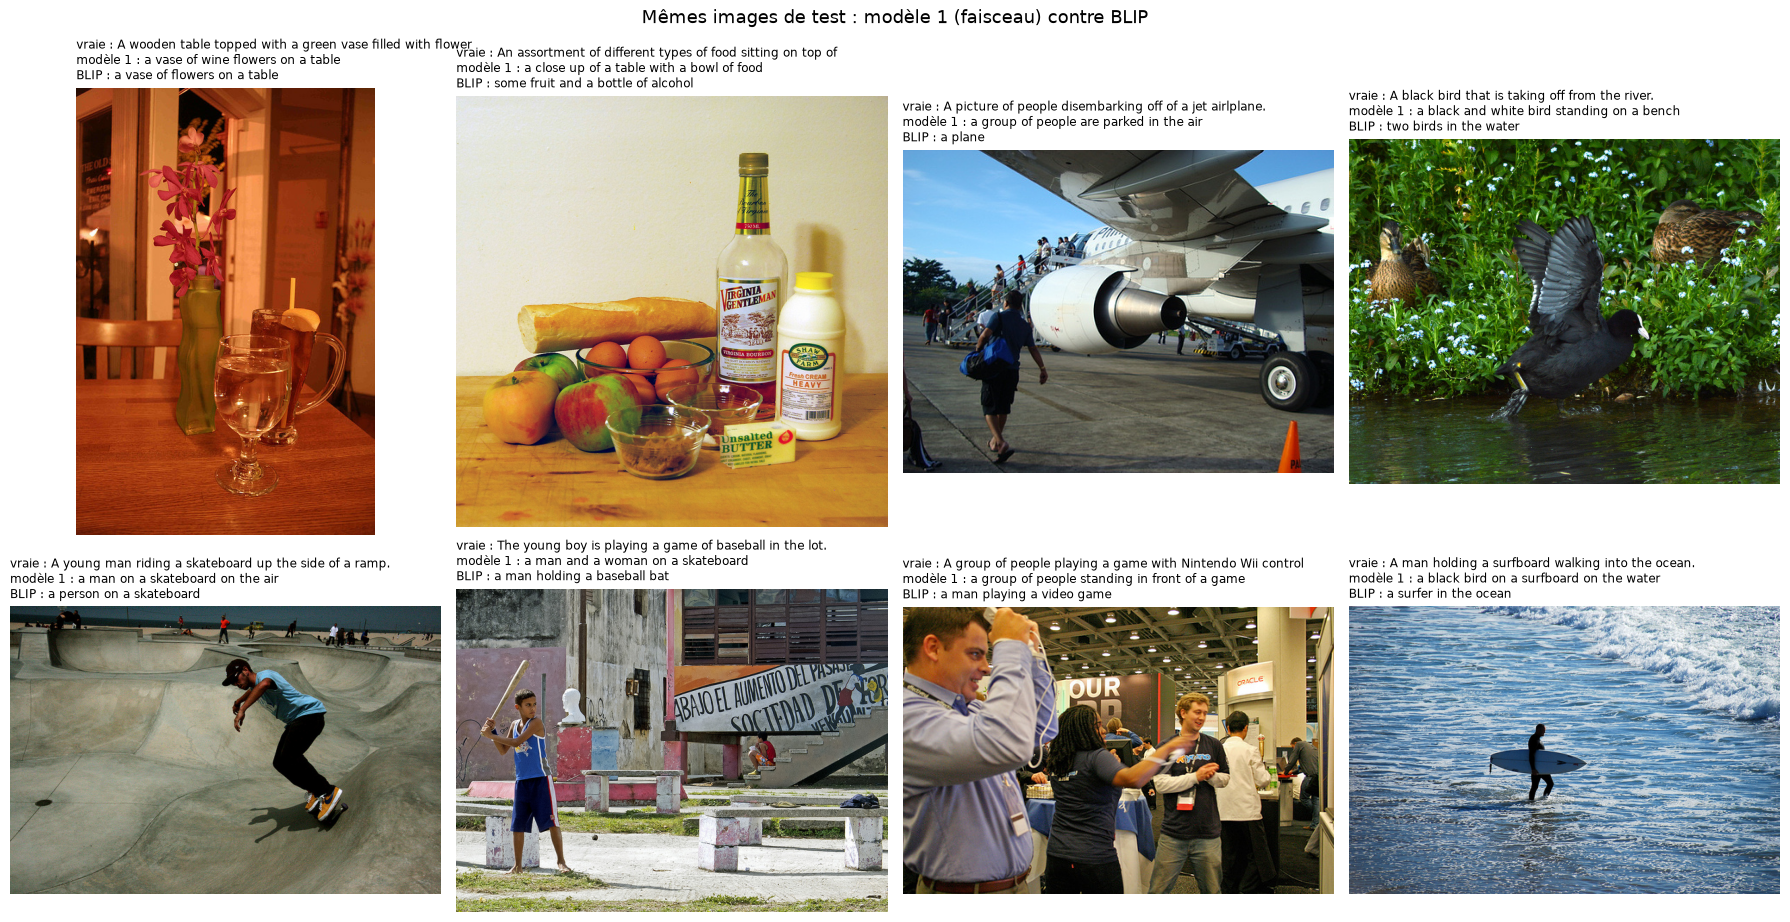

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, n in zip(axes.ravel(), exemples):
    k = images_test.index(n)
    ax.imshow(ouvrir(chemins_images[n])); ax.axis("off")
    ligne_m1 = f"modèle 1 : {m1_faisceau[k][:58]}\n" if modele_1 else ""
    ax.set_title(f"vraie : {legendes_par_image[n][0][:58]}\n{ligne_m1}BLIP : {blip_test[k][:58]}", fontsize=8.5, loc="left")
plt.suptitle("Mêmes images de test : modèle 1 (faisceau) contre BLIP" if modele_1 else "BLIP sur des images de test", fontsize=13)
plt.tight_layout(); plt.show()

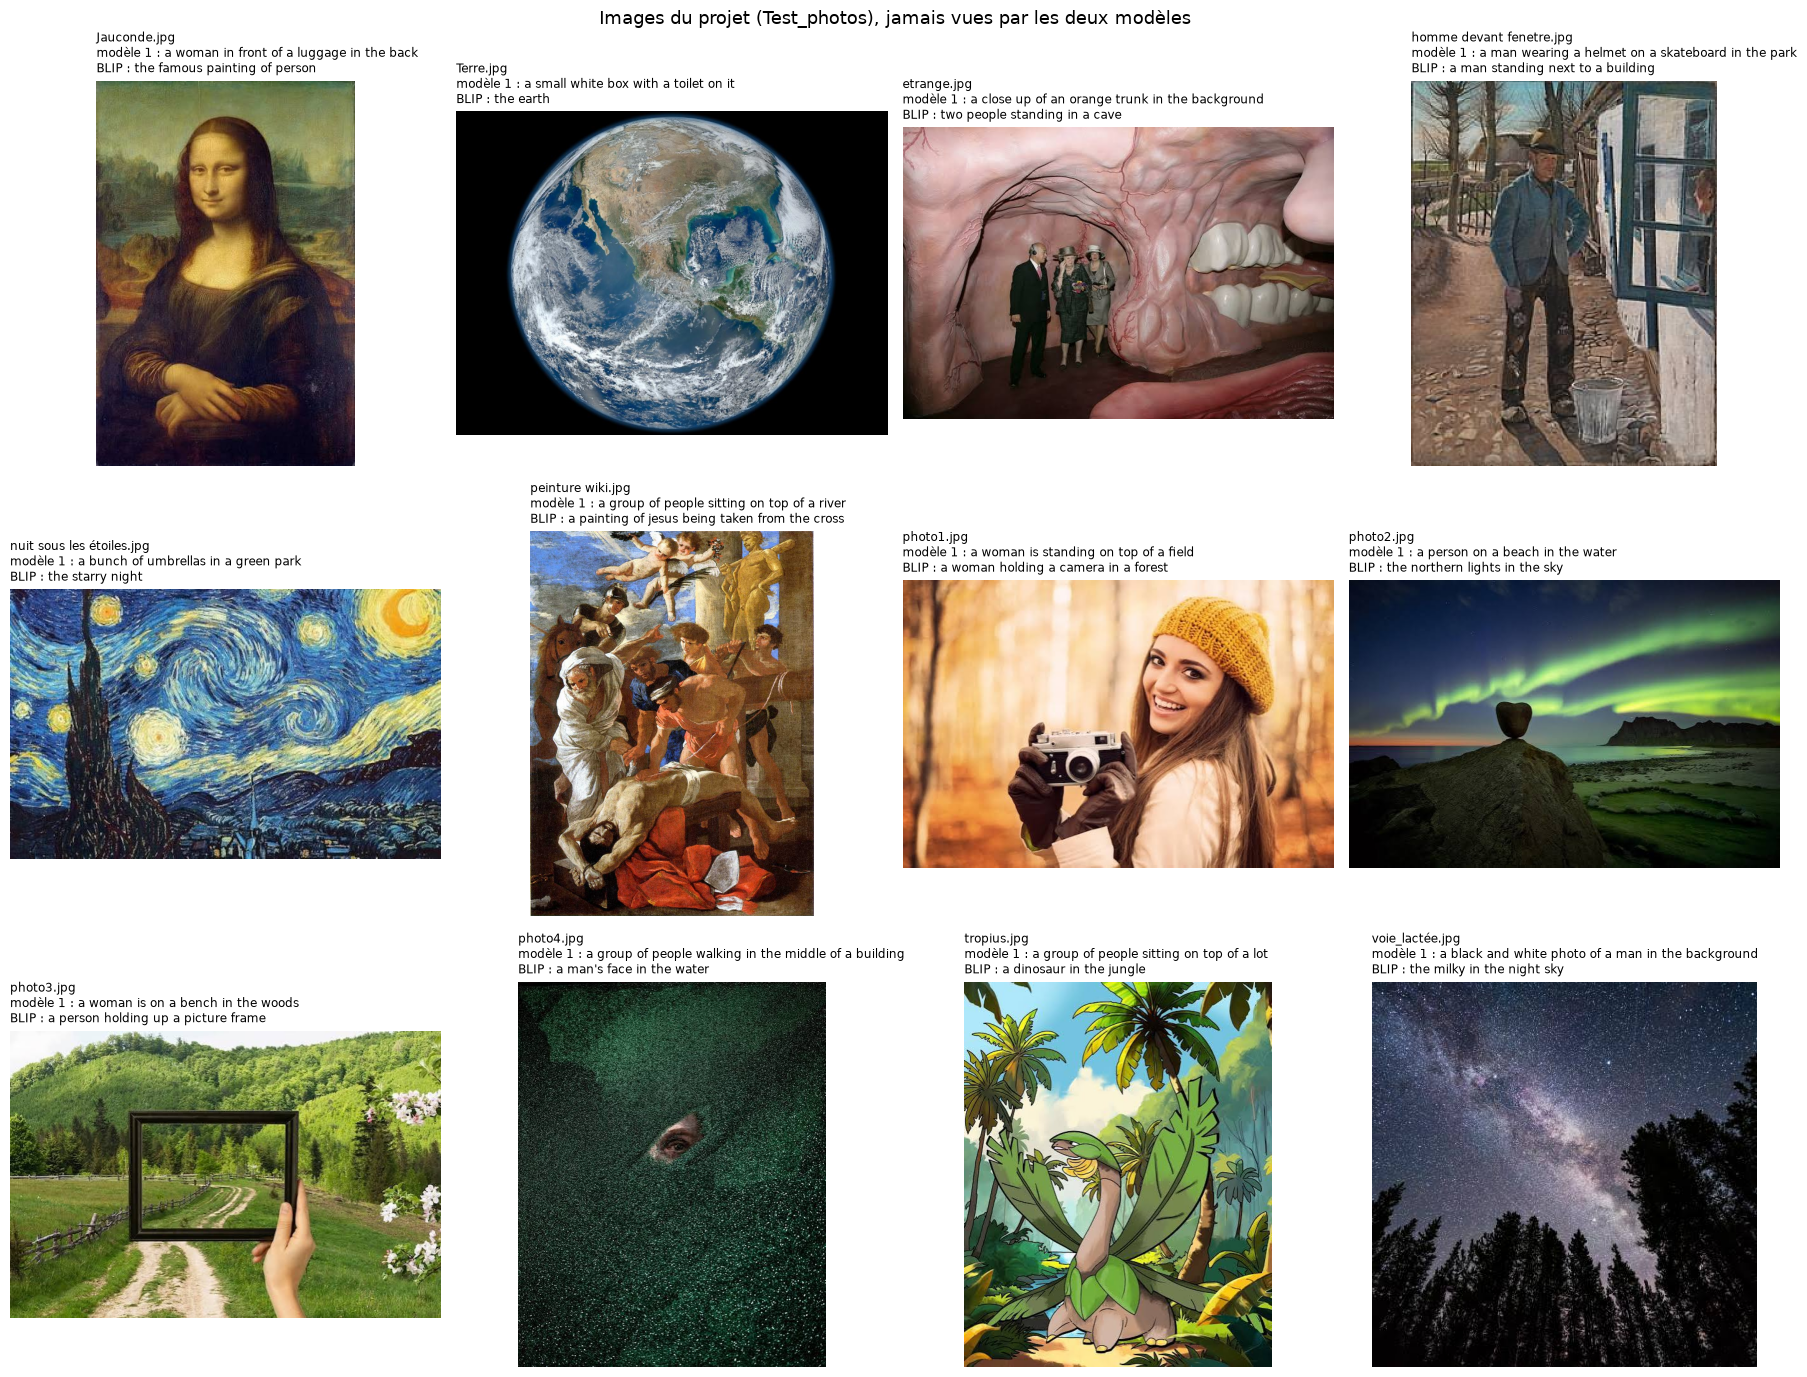

,image,modèle 1 (faisceau),BLIP
0,Jauconde.jpg,a woman in front of a luggage in the back,the famous painting of person
1,Terre.jpg,a small white box with a toilet on it,the earth
2,etrange.jpg,a close up of an orange trunk in the background,two people standing in a cave
3,homme devant fenetre.jpg,a man wearing a helmet on a skateboard in the ...,a man standing next to a building
4,nuit sous les étoiles.jpg,a bunch of umbrellas in a green park,the starry night
5,peinture wiki.jpg,a group of people sitting on top of a river,a painting of jesus being taken from the cross
6,photo1.jpg,a woman is standing on top of a field,a woman holding a camera in a forest
7,photo2.jpg,a person on a beach in the water,the northern lights in the sky
8,photo3.jpg,a woman is on a bench in the woods,a person holding up a picture frame
9,photo4.jpg,a group of people walking in the middle of a b...,a man's face in the water


In [9]:
fichiers_projet = sorted(p for p in TEST_PHOTOS.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
blip_projet = legender_blip(fichiers_projet)
modele1_projet = [modele_1["projet"].get(p.name, "–") for p in fichiers_projet] if modele_1 else ["–"] * len(fichiers_projet)
fig, axes = plt.subplots(3, 4, figsize=(18, 14))
for ax, p, l1, l2 in zip(axes.ravel(), fichiers_projet, modele1_projet, blip_projet):
    ax.imshow(ouvrir(p)); ax.axis("off")
    ax.set_title(f"{p.name}\nmodèle 1 : {l1[:55]}\nBLIP : {l2[:55]}", fontsize=8.5, loc="left")
plt.suptitle("Images du projet (Test_photos), jamais vues par les deux modèles", fontsize=13)
plt.tight_layout(); plt.show()
pd.DataFrame({"image": [p.name for p in fichiers_projet], "modèle 1 (faisceau)": modele1_projet, "BLIP": blip_projet})

,BLEU-1,BLEU-4,légendes distinctes,mots utilisés,phrases recopiées de l'entraînement,ms par image
modèle,,,,,,
légende humaine (1 contre 4),0.632,0.202,99%,873,1%,–
"modèle 1, glouton, images d'entraînement",0.712,0.292,93%,278,2%,–
"modèle 1, glouton, test",0.591,0.191,91%,224,1%,2
"modèle 1, faisceau, test",0.622,0.211,89%,250,3%,257
"BLIP (amorce retirée), test",0.562,0.281,90%,351,3%,96


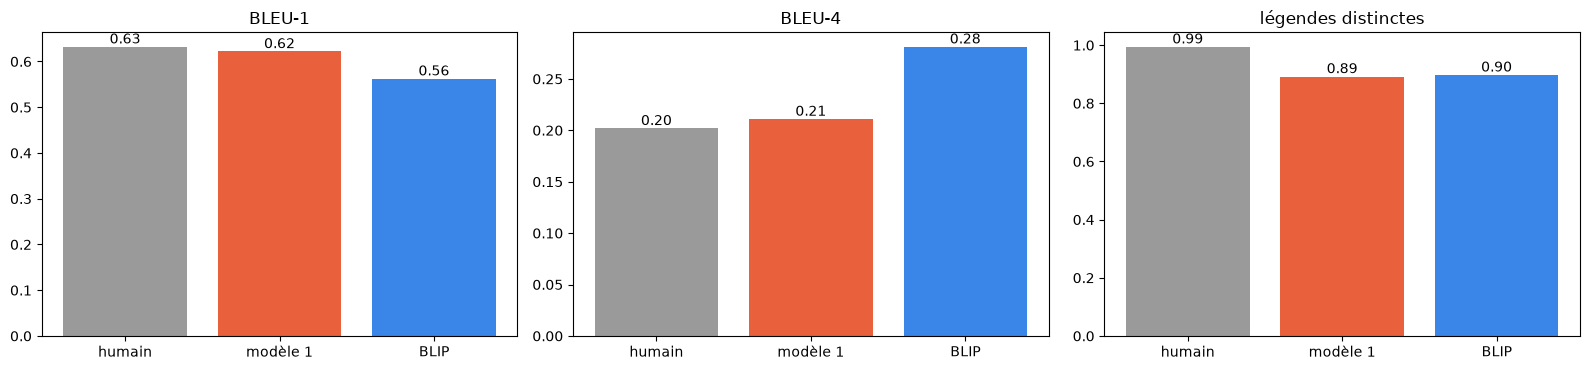

In [10]:
# Récapitulatif chiffré (BLEU sur le jeu de test, diversité, temps de calcul)
recap = resultats[["BLEU-1", "BLEU-4", "légendes distinctes", "mots utilisés", "phrases recopiées de l'entraînement", "ms par image"]]
formats = {"BLEU-1": "{:.3f}", "BLEU-4": "{:.3f}", "légendes distinctes": "{:.0%}", "mots utilisés": "{:.0f}",
           "phrases recopiées de l'entraînement": "{:.0%}", "ms par image": "{:.0f}"}
display(pd.DataFrame({c: recap[c].map(lambda v, f=f: "–" if pd.isna(v) else f.format(v)) for c, f in formats.items()}))

choix = [("légende humaine (1 contre 4)", "humain", "#9a9a9a"), ("modèle 1, faisceau, test", "modèle 1", "#e8613c"),
         ("BLIP (amorce retirée), test", "BLIP", "#3a86e8")]
choix = [c for c in choix if c[0] in resultats.index]
lignes, etiq, couleurs = (list(t) for t in zip(*choix))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col in zip(ax, ["BLEU-1", "BLEU-4", "légendes distinctes"]):
    a.bar(etiq, resultats.loc[lignes, col], color=couleurs)
    a.set_title(col); a.set_ylim(0, 1.05 * max(1e-3, resultats.loc[lignes, col].max()))
    for x, v in enumerate(resultats.loc[lignes, col]):
        a.text(x, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 10. Conclusion

| | Modèle 1 : CNN + attention + GRU (workshops) | **BLIP (retenu)** |
|---|---|---|
| Paramètres | 6,4 M entraînés ici (+ 4 M gelés dans EfficientNetB0) | 224 M, pré-entraînés : aucun entraînement à faire |
| Entraînement | 29 min (processeur seul) pour 8 époques, arrêté par le sur-apprentissage | aucun |
| BLEU-4, 362 images de test COCO | 0,209 | **0,282** |
| BLEU-1, mêmes images | **0,625** | 0,564 |
| Mots différents employés | 241 | **351** |
| Images du projet décrites correctement (notre lecture, tableau ci-dessous) | 0 sur 12 (4 en partie) | **9 sur 12** (3 en partie) |
| Temps par image (processeur 2 cœurs, sans carte graphique) | 0,7 s en faisceau | 2,1 s |

BLIP fait mieux sur la mesure la plus exigeante (BLEU-4, suites de 4 mots justes). Son BLEU-1 est plus bas parce que
ses légendes sont plus courtes une fois l'amorce retirée (6 mots en moyenne, contre 9 pour le modèle 1 et 11 pour
les humains) : BLEU pénalise les phrases plus courtes que les références, même exactes. L'écart décisif est
ailleurs : BLIP décrit **ce qu'il y a dans l'image**, y compris hors de COCO, là où le modèle 1 récite des phrases
COCO.

**Lecture des légendes sur les images du projet** (juste : la phrase décrit correctement l'image ; en partie : un
élément juste, le reste faux ou manquant) :

| Image | Modèle 1 | verdict | BLIP | verdict |
|---|---|---|---|---|
| Jauconde.jpg | a woman in front of a luggage in the back | en partie | the famous painting of person | juste |
| Terre.jpg | a small white box with a toilet on it | faux | the earth | juste |
| etrange.jpg | a couple of people are standing on the ground | en partie | two people standing in a cave | en partie |
| homme devant fenetre.jpg | a man wearing a helmet on a skateboard in the park | faux | a man standing next to a building | juste |
| nuit sous les étoiles.jpg | a bunch of umbrellas on a green park | faux | the starry night | juste |
| peinture wiki.jpg | a group of people sitting on top of a river | faux | a painting of jesus being taken from the cross | juste |
| photo1.jpg | a woman standing on top of a black park | en partie | a woman holding a camera in a forest | juste |
| photo2.jpg | a person on a beach with a body of water | faux | the northern lights in the sky | juste |
| photo3.jpg | a woman is holding a tennis racket | en partie | a person holding up a picture frame | juste |
| photo4.jpg | a group of people standing in the grass with a tree | faux | a man's face in the water | en partie |
| tropius.jpg | a group of people sitting on a table | faux | a dinosaur in the jungle | juste |
| voie_lactée.jpg | a black and white photo of a man in the background | faux | the milky in the night sky | en partie |

**Décision : le livrable 3 utilise BLIP** (`Salesforce/blip-image-captioning-base`), enregistré dans
`models/blip-captioning-base`. C'est lui que chargent l'onglet **L3 Légendes** du site (avec ses réglages de
génération) et l'étape 3 de la pipeline, par le serveur local `Test_website/serveur.py`. Le modèle 1 reste
enregistré dans `models/` (`l3_attention_*`) pour la comparaison.

**Limites de BLIP**, à garder en tête :

* il écrit en anglais (légendes d'entraînement anglaises) : une traduction automatique serait une étape de plus ;
* ses légendes sont courtes et parfois génériques (« the famous painting of person ») ou maladroites (« the milky
  in the night sky ») ;
* il a été affiné sur le jeu d'entraînement de COCO : son score sur nos images de test COCO est un peu optimiste
  (d'où la comparaison sur les images du projet) ;
* 224 M de paramètres : il lui faut une carte graphique pour légender un gros lot rapidement.

**Pistes** : la version large de BLIP, ou BLIP-2 ; un affinage sur des images TouNum légendées à la main ; des
amorces adaptées au type d'image donné par le livrable 1 (« a photograph of » pour une photo).

### Enregistrement de BLIP dans `models/`

Comme pour les autres livrables, le modèle retenu est enregistré dans `models/`, avec son processeur (taille d'image,
normalisation, vocabulaire) : `save_pretrained` écrit la configuration, les poids (`model.safetensors`, 224 millions
de paramètres en float32, environ 900 Mo) et les fichiers du tokenizer. Le site de test (onglet L3 et pipeline) et le
serveur local `Test_website/serveur.py` chargent ce dossier, sans connexion à Internet.

La version utilisée par le site est déjà enregistrée : la cellule ne la réécrit que si elle manque, ou si
`L3_SAUVER_BLIP=1`.

In [11]:
if (BLIP_DIR / "model.safetensors").is_file() and os.environ.get("L3_SAUVER_BLIP", "0") != "1":
    print(f"BLIP déjà enregistré dans {BLIP_DIR.resolve()} : rien à faire (L3_SAUVER_BLIP=1 pour le réécrire)")
else:
    BLIP_DIR.mkdir(parents=True, exist_ok=True)
    blip_model.to(torch.float32).save_pretrained(BLIP_DIR)    # enregistré en float32, comme le modèle publié
    blip_processor.save_pretrained(BLIP_DIR)
    blip_model.to(dtype_blip)
    print(f"BLIP enregistré dans {BLIP_DIR.resolve()}")
for f in sorted(BLIP_DIR.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size / 2**20:8.1f} Mo")

# Vérification : le modèle relu depuis le disque donne la même légende que celui qui vient de servir.
# (sous WSL, relu depuis sa copie sur le disque Linux, mise à jour si models/ a changé : voir copie_locale)
dossier_relu = copie_locale(BLIP_DIR)
try:
    relu = BlipForConditionalGeneration.from_pretrained(dossier_relu, dtype=dtype_blip)
except TypeError:
    relu = BlipForConditionalGeneration.from_pretrained(dossier_relu, torch_dtype=dtype_blip)
relu = relu.to(blip_device).eval()
proc = BlipProcessor.from_pretrained(dossier_relu)
x = proc(images=ouvrir(fichiers_projet[0]), text=AMORCE, return_tensors="pt").to(blip_device)
with torch.inference_mode(), torch.autocast(blip_device.type, dtype=torch.float16, enabled=blip_device.type == "cuda"):
    lu = proc.decode(relu.generate(**x, **REGLAGES_BLIP)[0], skip_special_tokens=True, clean_up_tokenization_spaces=True)
print("Relu depuis models/ :", lu)
print("Même légende que le modèle chargé plus haut :", lu[len(AMORCE):].strip() == legender_blip([fichiers_projet[0]], lot=1)[0])
del relu
gc.collect()
if blip_device.type == "cuda":
    torch.cuda.empty_cache()

BLIP déjà enregistré dans /mnt/d/A5/projet/models/blip-captioning-base : rien à faire (L3_SAUVER_BLIP=1 pour le réécrire)
  config.json                       0.0 Mo
  generation_config.json            0.0 Mo
  model.safetensors               854.4 Mo
  processor_config.json             0.0 Mo
  tokenizer.json                    0.7 Mo
  tokenizer_config.json             0.0 Mo


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Relu depuis models/ : a photograph of the famous painting of person
Même légende que le modèle chargé plus haut : True
